In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
gene_info = pd.read_csv("precise_mg1655-gene_info.csv", sep=",", header=0)
gene_info_dic = {}
for i in range(len(gene_info)):
    gene_info_dic[gene_info.iloc[i, 0]] = gene_info.iloc[i, 1]
gene_info_dic

{'b0001': 'thrL',
 'b0002': 'thrA',
 'b0003': 'thrB',
 'b0004': 'thrC',
 'b0005': 'yaaX',
 'b0006': 'yaaA',
 'b0007': 'yaaJ',
 'b0008': 'talB',
 'b0009': 'mog',
 'b0010': 'satP',
 'b0011': 'yaaW',
 'b0012': 'mbiA',
 'b0013': 'yaaI',
 'b0014': 'dnaK',
 'b0015': 'dnaJ',
 'b0016': 'insL1',
 'b0018': 'mokC',
 'b0019': 'nhaA',
 'b0020': 'nhaR',
 'b0021': 'insB1',
 'b0022': 'insA1',
 'b0023': 'rpsT',
 'b0024': 'yaaY',
 'b0025': 'ribF',
 'b0026': 'ileS',
 'b0027': 'lspA',
 'b0028': 'fkpB',
 'b0029': 'ispH',
 'b0030': 'rihC',
 'b0031': 'dapB',
 'b0032': 'carA',
 'b0033': 'carB',
 'b0034': 'caiF',
 'b0035': 'caiE',
 'b0036': 'caiD',
 'b0037': 'caiC',
 'b0038': 'caiB',
 'b0039': 'caiA',
 'b0040': 'caiT',
 'b0041': 'fixA',
 'b0042': 'fixB',
 'b0043': 'fixC',
 'b0044': 'fixX',
 'b0045': 'yaaU',
 'b0046': 'kefF',
 'b0047': 'kefC',
 'b0048': 'folA',
 'b0049': 'apaH',
 'b0050': 'apaG',
 'b0051': 'rsmA',
 'b0052': 'pdxA',
 'b0053': 'surA',
 'b0054': 'lptD',
 'b0055': 'djlA',
 'b0056': 'yabP',
 'b0057'

In [ ]:
trns = pd.read_csv("precise_mg1655-trn.csv", sep=",", header=0)
trn_clean = trns[
    trns["regulator_id"].notna() &
    trns["evidence"].notna() &
    trns["target_id"].notna()
]
# evidence: Weak-0, Strong-1, Confirmed-2
# remove all NaN in regulator_id, target_id, evidence

In [ ]:
trn_clean

,regulator_id,regulator_name,target_id,target_name,effect,magnitude,source,evidence
0,b3243,AaeR,b3240,aaeB,activation,NaN,RegulonDB_TF,0.0
1,b3243,AaeR,b3241,aaeA,activation,NaN,RegulonDB_TF,0.0
2,b3243,AaeR,b3242,aaeX,activation,NaN,RegulonDB_TF,0.0
3,b3255,AccB,b3255,accB,repression,NaN,RegulonDB_TF,0.0
4,b3255,AccB,b3256,accC,repression,NaN,RegulonDB_TF,0.0
...,...,...,...,...,...,...,...,...
9403,b4046,Zur,b1857,znuA,repression,NaN,RegulonDB_TF,1.0
9404,b4046,Zur,b1858,znuC,repression,NaN,RegulonDB_TF,1.0
9405,b4046,Zur,b1859,znuB,repression,NaN,RegulonDB_TF,1.0
9406,b4046,Zur,b1973,zinT,repression,NaN,RegulonDB_TF,0.0


In [181]:
regulator = trn_clean["regulator_id"].unique()
regulated_dic = {} # regulator: (regulated targets)
for reg in regulator:
    targets = set(trn_clean[trn_clean["regulator_id"] == reg]["target_id"].unique())
    if reg in targets:
        targets.remove(reg)
    regulated_dic[reg] = targets

In [155]:
# Gene expression tpm
tpm = pd.read_csv("precise_mg1655-log_tpm.csv", sep=",", header=0)
tpm_dic = {}
for i in range(len(tpm)):
    tpm_dic[tpm.iloc[i, 0]] = np.asarray(tpm.iloc[i, 1:].values, dtype=float)
tpm_dic

{'b0001': array([-5.08209850e-01,  1.78048906e+00,  7.22801635e-01,  1.47641431e+00,
         2.38364232e+00,  4.11213311e+00,  3.73074626e+00, -1.96989945e-01,
        -9.97967055e-01,  1.09024178e+00,  1.13041433e+00,  3.40660971e+00,
        -5.47365210e-01,  2.42157723e+00,  1.11440994e+00,  9.84557215e-01,
         2.13830684e+00, -3.74975450e-02,  1.54390121e+00,  1.79471691e+00,
         2.18310928e+00,  1.17622721e+00,  2.23899019e+00,  1.44827629e-01,
         1.95184311e+00, -1.60467550e-02,  7.39203765e-01,  2.81126232e+00,
         4.05643657e+00,  1.86034743e+00,  2.26085590e+00,  1.13199336e+00,
         7.61226495e-01,  9.14986975e-01, -5.59166447e+00,  1.42402154e+00,
         3.38273418e+00,  1.42230162e+00,  3.63548109e+00,  3.06982620e+00,
         4.50519354e+00,  3.85950951e+00,  3.82456852e+00,  3.32846371e+00,
         4.66246283e+00, -5.55101843e+00,  4.50907978e+00, -9.90012315e-01,
        -8.77302145e-01,  1.21742155e+00,  1.28811342e+00,  2.98248020e-01,
   

In [261]:
def compute_coordination(regulators, targets_dic, expression_dic):
    coordination = pd.DataFrame(columns=["regulator_id", "degree", "coordination"])
    for reg in regulators:
        sum = 0
        hub_tpm = expression_dic[reg]
        targets = targets_dic[reg]
        k = len(targets)
        for target in targets:
            corr = np.corrcoef(hub_tpm, expression_dic[target])[0, 1]
            if np.isnan(corr):
                k -= 1
            else:
                sum += corr
        if k > 0:
            C = sum / k
            coordination.loc[len(coordination)] = {"regulator_id": reg, "degree": k, "coordination": C}
    return coordination

## degree of targets v.s. coordination

Regulon set of protein i: $N(i)=\{j: (i, j) \in regulon\}$

Ignore the self regulation

Expression coordination betwee hub and partners: $C_i = \frac{1}{N(i)}\sum_{j\in N(i)} corr(x_i, x_j)$

In [224]:
coordination = pd.DataFrame(columns=["regulator_id", "degree(#targets)", "coordination"])
for reg in regulator:
    sum = 0
    hub_tpm = tpm_dic[reg]
    targets = regulated_dic[reg]
    k = len(targets)
    for target in targets:
        corr = np.corrcoef(hub_tpm, tpm_dic[target])[0, 1]
        if np.isnan(corr):
            k -= 1
        else:
            sum += corr
    if k > 0:
        C = sum / k
        coordination.loc[len(coordination)] = {"regulator_id": reg, "degree(#targets)": k, "coordination": C}
coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,regulator_id,degree(#targets),coordination
0,b3243,3,0.561384
1,b3255,1,0.886127
2,b0464,13,0.107046
3,b2213,3,0.689937
4,b4116,8,0.113195
...,...,...,...
248,b1526,8,0.261993
249,b3010,23,0.022044
250,b3292,3,0.469996
251,b4004,22,0.262683


In [225]:
coordination = compute_coordination(regulator, regulated_dic, tpm_dic)
coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,regulator_id,degree(#targets),coordination
0,b3243,3,0.561384
1,b3255,1,0.886127
2,b0464,13,0.107046
3,b2213,3,0.689937
4,b4116,8,0.113195
...,...,...,...
248,b1526,8,0.261993
249,b3010,23,0.022044
250,b3292,3,0.469996
251,b4004,22,0.262683


In [226]:
cut = coordination[coordination["degree(#targets)"] < 200 ]
cut = cut[cut["degree(#targets)"] > 3 ]

In [227]:
cut[cut['regulator_id'] == 'b2537']

,regulator_id,degree(#targets),coordination
88,b2537,5,0.294267


#### Test if the slope is significant
H0: slope = 0, Ha: slope != 0

p-value of slope is 0.012 ==> okay. But degree is very skewed

In [229]:
reg.summary() # p value of slope = 0.012, r^2 = 0.037 with linear regression (cut data)

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           coordination   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     6.454
Date:                Sat, 26 Sep 2026   Prob (F-statistic):             0.0120
Time:                        14:15:43   Log-Likelihood:                 21.154
No. Observations:                 172   AIC:                            -38.31
Df Residuals:                     170   BIC:                            -32.01
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.3060      0.020     14.933      0.000       0.266       0.346
degree(#targets)    -0.0014      0.001     -2.541      0.012      -0.002      -0.000
==============================================================================
Omnibus:                        7.087   Durbin-Watson:                   1.837
Prob(Omnibus):                  0.029   Jarque-Bera (JB):                7.152
Skew:                           0.499   Prob(JB):                       0.0280
Kurtosis:                       3.012   Cond. No.                         48.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

C:\Users\24776\AppData\Local\Temp\ipykernel_39620\3903626853.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_log.params[1])


Slope: -0.04251618502675832


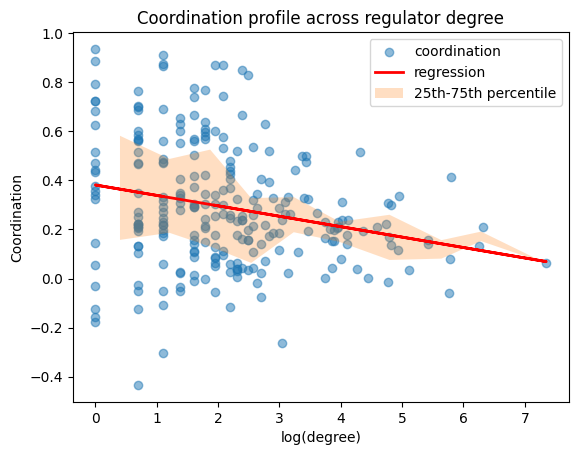

In [287]:
# Try log scale for degree, full data
X = coordination["degree(#targets)"].apply(lambda x: np.log(x))
y = coordination["coordination"]

plt.scatter(X, y, alpha=0.5)
reg_log = sm.OLS(y, sm.add_constant(X)).fit()
plt.plot(X, reg_log.predict(sm.add_constant(X)), color='red', linewidth=2)
print("Slope:", reg_log.params[1])

plt.title("Coordination vs Degree of Regulators in log scale")
plt.xlabel("log(degree)")
plt.ylabel("coordination")

df = coordination.copy()
df["log_degree"] = X
df["bin"] = pd.cut(df["log_degree"], bins=10)

profile = (
    df.groupby("bin", observed=True)
      .agg(
          log_degree=("log_degree", "mean"),
          median=("coordination", "median"),
          q25=("coordination", lambda x: x.quantile(0.25)),
          q75=("coordination", lambda x: x.quantile(0.75)),
          n=("coordination", "size")
      )
      .reset_index()
)

plt.fill_between(
    profile["log_degree"],
    profile["q25"],
    profile["q75"],
    alpha=0.25
)

plt.xlabel("log(degree)")
plt.ylabel("Coordination")
plt.legend(["coordination","regression", "25th-75th percentile"])
plt.title("Coordination profile across regulator degree")
plt.show()


**Comment**

r^2 is very low, but p-value is very significant. The model only explains a little coordiantion variation. There is a nagative correlatin, but barely linear. Try Spearman then

In [220]:
print(reg_log.pvalues)
reg_log.summary() # p value of slope = 1.085106e-04, r^2 = 0.058
# coordination ~ log(degree) with linear regression (full data)

const               7.756757e-33
degree(#targets)    1.085106e-04
dtype: float64


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           coordination   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.054
Method:                 Least Squares   F-statistic:                     15.47
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           0.000109
Time:                        14:03:17   Log-Likelihood:                 1.6812
No. Observations:                 253   AIC:                            0.6377
Df Residuals:                     251   BIC:                             7.704
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.3813      0.028     13.864      0.000       0.327       0.435
degree(#targets)    -0.0425      0.011     -3.933      0.000      -0.064      -0.021
==============================================================================
Omnibus:                        1.318   Durbin-Watson:                   1.808
Prob(Omnibus):                  0.517   Jarque-Bera (JB):                1.016
Skew:                           0.120   Prob(JB):                        0.602
Kurtosis:                       3.197   Cond. No.                         5.13
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

#### Spearman

Analysis of rank ==> monotonically decreasing trend

In [234]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    coordination["degree(#targets)"],
    coordination["coordination"],
    nan_policy="omit"
)

print("Spearman rho =", rho)
print("p =", p)

Spearman rho = -0.23751746795799783
p = 0.00013675761777412314


### Remove all the "housekeeper genes" ?

Overall OR Try to cluster the samples under some same conditions?

Try glucose(all concentrations) first

#### Glucose

In [243]:
meta = pd.read_csv("precise_mg1655-sample_table.csv", sep=",", header=0)

glucose_meta = meta[
    meta["Carbon Source (g/L)"]
        .astype(str)
        .str.contains("glucose", case=False, na=False)
]

glucose_id = glucose_meta['unique_identifier'] #401 samples ussing glucose as C source
#glucose_meta["Carbon Source (g/L)"].unique()

In [257]:
tpm_glucose = tpm[["gene_id"] + glucose_id.tolist()]
tpm_glucose_dic = {}
for i in range(len(tpm_glucose)):
    tpm_glucose_dic[tpm_glucose.iloc[i, 0]] = np.asarray(tpm_glucose.iloc[i, 1:].values, dtype=float)

In [262]:
coordination_glucose = compute_coordination(regulator, regulated_dic, tpm_glucose_dic)

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Slope: -0.04251618502675832


C:\Users\24776\AppData\Local\Temp\ipykernel_39620\4239169707.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_log_glucose.params[1])


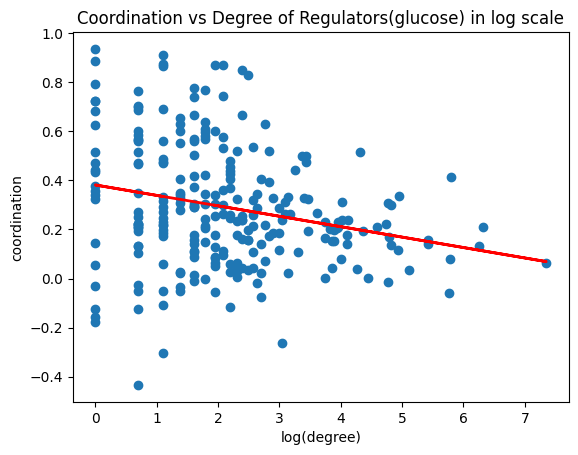

In [267]:
# Try log scale for degree, full data
X = coordination["degree(#targets)"].apply(lambda x: np.log(x))
y = coordination["coordination"]

plt.scatter(X, y)
reg_log_glucose = sm.OLS(y, sm.add_constant(X)).fit()
plt.plot(X, reg_log_glucose.predict(sm.add_constant(X)), color='red', linewidth=2)
print("Slope:", reg_log_glucose.params[1])

plt.title("Coordination vs Degree of Regulators(glucose) in log scale")
plt.xlabel("log(degree)")
plt.ylabel("coordination")
plt.show()

In [ ]:
print(reg_log_glucose.pvalues)
reg_log_glucose.summary() # p-value = 1.085106e-04, r^2 = 0.058
# Almost the same with the over all regulators
# maybe because the glucose samples are the majority of the samples in the dataset

const               7.756757e-33
degree(#targets)    1.085106e-04
dtype: float64


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           coordination   R-squared:                       0.058
Model:                            OLS   Adj. R-squared:                  0.054
Method:                 Least Squares   F-statistic:                     15.47
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           0.000109
Time:                        15:14:20   Log-Likelihood:                 1.6812
No. Observations:                 253   AIC:                            0.6377
Df Residuals:                     251   BIC:                             7.704
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.3813      0.028     13.864      0.000       0.327       0.435
degree(#targets)    -0.0425      0.011     -3.933      0.000      -0.064      -0.021
==============================================================================
Omnibus:                        1.318   Durbin-Watson:                   1.808
Prob(Omnibus):                  0.517   Jarque-Bera (JB):                1.016
Skew:                           0.120   Prob(JB):                        0.602
Kurtosis:                       3.197   Cond. No.                         5.13
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## degree of interaction v.s. coordination
Not significant, no correlation, no need to see it

In [193]:
interactions = pd.read_csv("string_physical_interaction.txt", sep=" ", header=0)
interactions["protein1"] = interactions["protein1"].apply(lambda x: x.split(".")[1])
interactions["protein2"] = interactions["protein2"].apply(lambda x: x.split(".")[1])

In [ ]:
interactions # what is the combined_score??

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
0,b0002,b0436,0,456,0,0,0,0,0,456
1,b0002,b0473,0,0,174,0,0,0,0,174
2,b0002,b1945,0,0,775,0,0,0,0,775
3,b0002,b2926,0,0,177,0,0,0,0,177
4,b0002,b3347,0,0,338,0,0,0,0,338
...,...,...,...,...,...,...,...,...,...,...
93703,b4602,b0432,0,0,0,900,0,0,0,900
93704,b4602,b0430,0,0,0,900,0,0,0,900
93705,b4602,b0429,0,0,0,900,0,0,0,900
93706,b4602,b4515,0,800,0,900,0,0,0,979


In [230]:
interactors = interactions["protein1"].unique()
interaction_dic = {} # regulator: (regulated targets)
for inter in interactors:
    targets = set(interactions[interactions["protein1"] == inter]["protein2"].unique())
    interaction_dic[inter] = targets
interaction_dic

{'b0002': {'b0436',
  'b0473',
  'b1945',
  'b2926',
  'b3347',
  'b3823',
  'b3940',
  'b4024',
  'b4052',
  'b4142',
  'b4207'},
 'b0004': {'b0104',
  'b0386',
  'b0931',
  'b1581',
  'b2508',
  'b2560',
  'b2600',
  'b2708',
  'b2779',
  'b3197',
  'b4388'},
 'b0006': {'b0587'},
 'b0007': {'b1078'},
 'b0008': {'b0071',
  'b0170',
  'b0688',
  'b2029',
  'b2195',
  'b2464',
  'b2465',
  'b2935',
  'b3781',
  'b3919',
  'b4085'},
 'b0009': {'b0782',
  'b0785',
  'b0827',
  'b1224',
  'b1727',
  'b1864',
  'b2231',
  'b2991',
  'b3856'},
 'b0011': {'b1073', 'b1778'},
 'b0014': {'b0015',
  'b0033',
  'b0049',
  'b0055',
  'b0059',
  'b0148',
  'b0168',
  'b0169',
  'b0177',
  'b0318',
  'b0375',
  'b0383',
  'b0419',
  'b0424',
  'b0436',
  'b0437',
  'b0438',
  'b0439',
  'b0448',
  'b0449',
  'b0473',
  'b0474',
  'b0489',
  'b0525',
  'b0605',
  'b0644',
  'b0646',
  'b0647',
  'b0649',
  'b0723',
  'b0771',
  'b0797',
  'b0838',
  'b0875',
  'b0881',
  'b0894',
  'b0911',
  'b0914',

In [232]:
coordination_interactions = compute_coordination(interactors, interaction_dic, tpm_dic)
coordination_interactions

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\li

,regulator_id,degree(#targets),coordination
0,b0002,11,0.323383
1,b0004,11,0.269440
2,b0006,1,0.035522
3,b0007,1,-0.313971
4,b0008,11,0.389392
...,...,...,...
3166,b4565,4,0.339048
3167,b4572,10,0.163026
3168,b4592,6,0.399832
3169,b4602,9,0.041970


Slope: -0.0032532668564507015


C:\Users\24776\AppData\Local\Temp\ipykernel_39620\511911702.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_log.params[1])


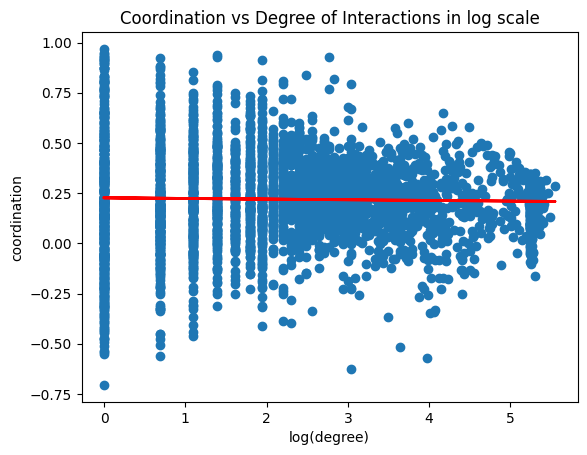

In [233]:
# Try log scale for degree, full data
X = coordination_interactions["degree(#targets)"].apply(lambda x: np.log(x))
y = coordination_interactions["coordination"]

plt.scatter(X, y)
reg_log = sm.OLS(y, sm.add_constant(X)).fit()
plt.plot(X, reg_log.predict(sm.add_constant(X)), color='red', linewidth=2)
print("Slope:", reg_log.params[1])

plt.title("Coordination vs Degree of Interactions in log scale")
plt.xlabel("log(degree)")
plt.ylabel("coordination")
plt.show()